In [ ]:
import os
from google.colab import drive

In [ ]:
!pip install -U albumentations

In [ ]:
drive.mount('/content/drive')
BASE_PATH = '/content/drive/My Drive/EVAHAN/img_benchmark_Decembre25/'

Mounted at /content/drive


In [ ]:
IMGS_PATH = os.path.join(BASE_PATH, 'imgs')
os.listdir(IMGS_PATH)

['1stPaperANTExtractComparaison.png',
 'KKaroubi.png',
 'Dedekind.png',
 'Bourbaki.png',
 'BourbakiZoom.png',
 'riemannnobili3.png',
 'ChambertLoir Info.png',
 'SevenSketches.png',
 'HighDimStat.png',
 'RiemannianGeo.png',
 'Brudern1.png',
 'Brudern2.png',
 'Brudern3.png',
 'Brudern4.png',
 'legendreJacobi1.png',
 'legendreJacobi2.png',
 'Bourbaki1.png',
 'Bourbaki2.png',
 'Bourbaki3.png',
 'Bourbaki5.png',
 'Bourbaki6.png',
 'Bourbaki7.png',
 'Bourbaki8.png',
 'bourbaki9.png',
 'bourbaki10.png',
 'Cauchy1.png',
 'Cauchy2.png',
 'Cauchy3.png',
 'Cauchy4.png',
 'Cauchy5.png',
 'Cauchy6.png',
 'LanglandsWeil1.png',
 'LanglandsWeil2.png',
 'LanglandsWeil3.png',
 'Fresan_cours_6.jpg',
 'Fresan_cours_7.jpg',
 'Fresan_cours_5.jpg',
 'Fresan_cours_3.jpg',
 'Fresan_cours_2.jpg',
 'Fresan_cours_4.jpg',
 'Fresan_cours_1.jpg',
 'Fresan_cours_8.jpg',
 'Fresan_cours_9.jpg',
 'VolterraPicard1.2.jpg',
 'DelignelettreaWeilIAS_1.jpg',
 'DelignelettreaWeilIAS_2.jpg',
 'Deligne_on_fiber_functorsMILNE_5.j

In [ ]:
import cv2
import random
import numpy as np
import albumentations as A
import matplotlib.pyplot as plt
from skimage.metrics import structural_similarity as ssim
from albumentations.core.transforms_interface import ImageOnlyTransform

class GeometricInkBlotTransform(ImageOnlyTransform):
    def __init__(self, max_holes=3, min_size=15, max_size=50, always_apply=False, p=0.5):
        super().__init__(always_apply=always_apply, p=p)
        self.max_holes = max_holes
        self.min_size = min_size
        self.max_size = max_size

    def apply(self, img, **params):

        img = img.copy()
        h, w = img.shape[:2]
        num_holes = random.randint(1, self.max_holes)

        for _ in range(num_holes):

            cx = random.randint(0, w)
            cy = random.randint(0, h)
            size = random.randint(self.min_size, self.max_size)


            g = random.randint(0, 120)
            color = (g, g, g) if len(img.shape) == 3 else g

            shape_type = random.choice(['sphere', 'star', 'polygon'])
            if shape_type == 'sphere':
                rx = size // 2
                ry = int(rx * random.uniform(0.6, 1.0))
                angle = random.randint(0, 180)
                cv2.ellipse(img, (cx, cy), (rx, ry), angle, 0, 360, color, -1)

            # elif shape_type == 'rectangle':
            #     rw = size
            #     rh = int(size * random.uniform(0.4, 1.0))
            #     rect = ((cx, cy), (rw, rh), random.randint(0, 180))
            #     box = cv2.boxPoints(rect).astype(np.int32)
            #     cv2.fillPoly(img, [box], color)

            elif shape_type == 'star':
                num_points = random.choice([5, 6, 7])
                r_outer = size // 2
                r_inner = r_outer // 2
                points = []
                angle_step = np.pi / num_points
                start_angle = random.uniform(0, 2 * np.pi)

                for i in range(2 * num_points):
                    r = r_outer if i % 2 == 0 else r_inner
                    r = int(r * random.uniform(0.8, 1.2))
                    a = start_angle + i * angle_step + random.uniform(-0.05, 0.05)
                    x = int(cx + r * np.cos(a))
                    y = int(cy + r * np.sin(a))
                    points.append([x, y])

                cv2.fillPoly(img, [np.array(points, dtype=np.int32)], color)

            elif shape_type == 'polygon':
                num_vertices = random.randint(5, 25)
                points = []
                for _ in range(num_vertices):
                    x = cx + random.randint(-size // 8, size // 8)
                    y = cy + random.randint(-size // 8, size // 8)
                    points.append([x, y])
                hull = cv2.convexHull(np.array(points, dtype=np.int32))
                cv2.fillPoly(img, [hull], color)

        return img

def cv2_imshow(img):
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.show()

# transform = A.Compose([
#     # 1. Geometric distortion
#     A.ElasticTransform(alpha=1, sigma=50, alpha_affine=50, p=0.5),
#     A.Perspective(scale=(0.05, 0.1), p=0.5),

#     # 2. Ink effects (Bleeding)
#     A.OneOf([
#         A.GaussianBlur(blur_limit=(3, 5), p=1.0),
#         A.MotionBlur(blur_limit=5, p=1.0),
#     ], p=0.3),

#     # 3. Paper Aging
#     A.HueSaturationValue(hue_shift_limit=10, sat_shift_limit=20, val_shift_limit=10, p=1.0), # Yellowing
#     A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.5),

#     # 4. Physical damage (Foxing spots)
#     A.CoarseDropout(max_holes=10, max_height=20, max_width=20,
#         fill_value=(139, 69, 19), p=0.2), # Brown spots
# ])

# Foxing, fungi, yellowing, paper grain, humidity marks, Fading, bleed-through,
# feathering, pressure variations, Elastic deformation, perspective,
# binding curvature, shear, Gaussian noise, scan lines, motion blur, shadows,
# JPEG compression, thresholding (photocopy look)
# transform = A.Compose([
#     A.OneOf([
#         # Binding curvature & Page folds
#         A.GridDistortion(num_steps=5, distort_limit=0.15, p=1.0),
#         # Perspective & Shear
#         A.Perspective(scale=(0.05, 0.12), keep_size=True, p=1.0),
#         A.Affine(shear={'x': (-10, 10), 'y': (-10, 10)}, p=1.0),
#     ], p=0.8),

#     A.ElasticTransform(alpha=1, sigma=50, alpha_affine=30, p=0.4),

#     A.HueSaturationValue(
#         hue_shift_limit=15,
#         sat_shift_limit=30,
#         val_shift_limit=10,
#         p=1.0
#     ),
#     A.GaussNoise(var_limit=(10.0, 50.0), p=0.5),

#     A.RandomGamma(gamma_limit=(80, 120), p=0.5),
#     A.RandomBrightnessContrast(brightness_limit=0.1, contrast_limit=0.2, p=0.5),

#     A.OneOf([
#         A.GaussianBlur(blur_limit=(3, 5), p=1.0),
#         A.MotionBlur(blur_limit=5, p=1.0),
#         A.ZoomBlur(max_factor=1.02, p=1.0), # Slight lens blur
#     ], p=0.4),

#     A.Emboss(alpha=(0.2, 0.5), strength=(0.2, 0.7), p=0.2),

#     A.Spatter(
#         mean=0.65, std=0.3, gauss_sigma=2, cut_out_threshold=0.68,
#         intensity=0.6, mode='rain', color=(139, 69, 19), p=0.3
#     ),
#     A.Spatter(
#         mean=0.5, std=0.2, gauss_sigma=45, cut_out_threshold=0.8,
#         intensity=0.2, mode='mud', color=(200, 180, 150), p=0.2
#     ),

#     A.RandomShadow(
#         shadow_roi=(0, 0, 1, 1),
#         num_shadows_lower=1,
#         num_shadows_upper=2,
#         shadow_dimension=5,
#         p=0.4
#     ),
#     A.MultiplicativeNoise(multiplier=(0.9, 1.1), per_channel=True, p=0.05),

#     A.ImageCompression(quality_lower=60, quality_upper=90, p=0.3),

#     A.Posterize(num_bits=4, p=0.1),
# ])

transform = A.Compose([
    A.OneOf([
        # Micro page-folds & page curvature
        A.GridDistortion(num_steps=7, distort_limit=0.08, p=1.0),
        # Moderate perspective/shear (simulating off-center mobile phone captures)
        A.Perspective(scale=(0.02, 0.06), keep_size=True, p=1.0),
        A.Affine(shear={'x': (-6, 6), 'y': (-6, 6)}, rotate=(-3, 3), p=1.0),
    ], p=0.7),

    # Tightly constrained ElasticTransform to simulate crinkles without splitting characters
    A.ElasticTransform(alpha=0.5, sigma=30, alpha_affine=15, p=0.3),

    # Math documents mix thin lines (fraction bars, limits) with heavy pooling (integrals, big brackets)
    A.OneOf([
        # Erosion: simulates thin, fading ink where fraction lines or dots might fragment
        A.Morphological(operation="erosion", scale=(1, 2), p=1.0),
        # Dilation: simulates heavy ink pooling on deliberate structures like \sum or \int
        A.Morphological(operation="dilation", scale=(1, 2), p=1.0),
    ], p=0.4),

    A.HueSaturationValue(hue_shift_limit=10, sat_shift_limit=25, val_shift_limit=10, p=1.0),
    # Finer grain variance ensures tiny standalone components (like decimal points) don't get drowned out
    A.GaussNoise(var_limit=(5.0, 30.0), p=0.4),

    # Simulates speed variations (fast cursive variables vs highly intentional mathematical symbols)
    A.RandomGamma(gamma_limit=(85, 115), p=0.4),
    A.RandomBrightnessContrast(brightness_limit=0.1, contrast_limit=0.15, p=0.5),

    # Safe Feathering (Strictly limits kernel size so minus signs do not vanish)
    A.OneOf([
        A.GaussianBlur(blur_limit=(3, 3), p=1.0),
        A.MotionBlur(blur_limit=3, p=1.0),
    ], p=0.3),

    # Instead of square holes, this mimics crossed-out derivation mistakes and stray pen slips
    # A.OneOf([
    #     # Horizontal strike-throughs (long, thin dark shapes cutting through formulas)
    #     # A.CoarseDropout(max_holes=2, min_height=1, max_height=3, min_width=30, max_width=100,
    #     #                 fill_value=(25, 25, 25), p=1.0),
    #     # # Stray pen marks / ink blots
    #     A.CoarseDropout(max_holes=4, min_height=3, max_height=7, min_width=3, max_width=7,
    #                     fill_value=(35, 25, 20), p=1.0),

    #     # Horizontal strike-throughs for crossed-out equations
    #     A.CoarseDropout(max_holes=2, min_height=1, max_height=3, min_width=30, max_width=100,
    #                     fill_value=(30, 30, 30), p=1.0),
    # ], p=0.25),

    GeometricInkBlotTransform(max_holes=17, min_size=20, max_size=65, p=0.40),


    A.Spatter(mean=0.6, std=0.2, gauss_sigma=2, cut_out_threshold=0.7,
              intensity=0.5, mode='rain', color=(130, 65, 25), p=0.2), # Foxing spots

    A.RandomShadow(shadow_roi=(0, 0, 1, 1), num_shadows_lower=1, num_shadows_upper=2,
                   shadow_dimension=4, p=0.3),

    A.ImageCompression(quality_lower=75, quality_upper=95, p=0.3),

    # Rare high-contrast "Xerox/Photocopy" look that mimics broken binary scans
    A.Posterize(num_bits=5, p=0.08),
])

def quantify_transform_impact(orig_img, aug_img):

    if orig_img.shape != aug_img.shape:
        aug_img = cv2.resize(aug_img, (orig_img.shape[1], orig_img.shape[0]))

    mse_score = np.mean((orig_img.astype("float") - aug_img.astype("float")) ** 2)

    orig_gray = cv2.cvtColor(orig_img, cv2.COLOR_BGR2GRAY) if len(orig_img.shape) == 3 else orig_img
    aug_gray = cv2.cvtColor(aug_img, cv2.COLOR_BGR2GRAY) if len(aug_img.shape) == 3 else aug_img

    ssim_score, diff_map = ssim(orig_gray, aug_gray, full=True)

    hist_dist = 0.0
    if len(orig_img.shape) == 3:
        hist_orig = cv2.calcHist([orig_img], [0, 1, 2], None, [8, 8, 8], [0, 256, 0, 256, 0, 256])
        hist_aug = cv2.calcHist([aug_img], [0, 1, 2], None, [8, 8, 8], [0, 256, 0, 256, 0, 256])
        cv2.normalize(hist_orig, hist_orig)
        cv2.normalize(hist_aug, hist_aug)
        hist_dist = cv2.compareHist(hist_orig, hist_aug, cv2.HISTCMP_BHATTACHARYYA)

    return {
        "MSE": float(mse_score),
        "SSIM": float(ssim_score),
        "Color_Shift": float(hist_dist)
    }

METRICS = {}

# file_name = "Fresan_cours_3.jpg"
# image = cv2.imread(os.path.join(IMGS_PATH, file_name))
# image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
# for i in range(12):
#     transformed = transform(image=image)
#     transformed_image = transformed["image"]
#     cv2_imshow(transformed_image)
#     metrics = quantify_transform_impact(image, transformed_image)
#     METRICS[f"{file_name.split(".")[0]}_synthetic_{i}.jpg"] = metrics
#     print(metrics)
# print(METRICS)

for idx, file_name in enumerate(os.listdir(IMGS_PATH)):
#file_name = "Fresan_cours_3.jpg"
  print(idx, " / ", len(os.listdir(IMGS_PATH)))

  image = cv2.imread(os.path.join(IMGS_PATH, file_name))
  image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

  #tests = []
  for i in range(1, 16):

    transformed = transform(image=image)
    transformed_image = transformed["image"]
    #cv2_imshow(transformed_image)
    metrics = quantify_transform_impact(image, transformed_image)
    METRICS[f"{file_name.split(".")[0]}_synthetic_{i}.jpg"] = metrics
    #tests.append(transformed_image)
    cv2.imwrite(f"/content/drive/My Drive/EVAHAN/img_benchmark_Decembre25/synthetic/{file_name.split(".")[0]}_synthetic_{i}.jpg", transformed_image)

/tmp/ipykernel_19564/751990626.py:195: UserWarning: Argument(s) 'alpha_affine' are not valid for transform ElasticTransform
  A.ElasticTransform(alpha=0.5, sigma=30, alpha_affine=15, p=0.3),
/tmp/ipykernel_19564/751990626.py:209: UserWarning: Argument(s) 'var_limit' are not valid for transform GaussNoise
  A.GaussNoise(var_limit=(5.0, 30.0), p=0.4),
/tmp/ipykernel_19564/751990626.py:11: UserWarning: Argument(s) 'always_apply' are not valid for transform BasicTransform
  super().__init__(always_apply=always_apply, p=p)
/tmp/ipykernel_19564/751990626.py:241: UserWarning: Argument(s) 'cut_out_threshold' are not valid for transform Spatter
  A.Spatter(mean=0.6, std=0.2, gauss_sigma=2, cut_out_threshold=0.7,
/tmp/ipykernel_19564/751990626.py:244: UserWarning: Argument(s) 'num_shadows_lower, num_shadows_upper' are not valid for transform RandomShadow
  A.RandomShadow(shadow_roi=(0, 0, 1, 1), num_shadows_lower=1, num_shadows_upper=2,
/tmp/ipykernel_19564/751990626.py:247: UserWarning: Argumen

0  /  60
1  /  60
2  /  60
3  /  60
4  /  60
5  /  60
6  /  60
7  /  60
8  /  60
9  /  60
10  /  60
11  /  60
12  /  60
13  /  60
14  /  60
15  /  60
16  /  60
17  /  60
18  /  60
19  /  60
20  /  60
21  /  60
22  /  60
23  /  60
24  /  60
25  /  60
26  /  60
27  /  60
28  /  60
29  /  60
30  /  60
31  /  60
32  /  60
33  /  60
34  /  60
35  /  60
36  /  60
37  /  60
38  /  60
39  /  60
40  /  60
41  /  60
42  /  60
43  /  60
44  /  60
45  /  60
46  /  60
47  /  60
48  /  60
49  /  60
50  /  60
51  /  60
52  /  60
53  /  60
54  /  60
55  /  60
56  /  60
57  /  60
58  /  60
59  /  60


In [ ]:
import csv
import itertools

fields = ['filename', 'MSE', 'SSIM', 'Color_Shift']
with open(os.path.join(BASE_PATH, "albu_impact.csv"), "w", newline='', encoding='utf-8') as f:
    w = csv.DictWriter(f, fields)
    w.writeheader()
    for k in METRICS:
        row_data = {'filename': k}
        row_data.update(METRICS[k])
        w.writerow(row_data)

In [ ]:
# Les TESTS AVEC POT / FIAOT sont pas forcément à regarder pour l'instant! (Je n'ai d'ailleurs pas inclus plein d'autres choses autour de l'OT)

In [ ]:
!git clone https://github.com/EricVerbeke/fast_image_alignment_ot.git

Cloning into 'fast_image_alignment_ot'...
remote: Enumerating objects: 204, done.
remote: Counting objects: 100% (204/204), done.
remote: Compressing objects: 100% (182/182), done.
remote: Total 204 (delta 86), reused 85 (delta 21), pack-reused 0 (from 0)
Receiving objects: 100% (204/204), 5.62 MiB | 23.57 MiB/s, done.
Resolving deltas: 100% (86/86), done.


In [ ]:
!pip install finufft pywavelets pot jax ott-jax

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.2/40.2 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 85.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 309.7/309.7 kB 33.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 172.4/172.4 kB 19.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 77.6/77.6 kB 9.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 121.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 85.0/85.0 MB 28.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 185.8/185.8 kB 22.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 kB 6.6 MB/s eta 0:00:00
  Attempting uninstall: jaxlib
    Found existing installation: jaxlib 0.7.2
    Uninstalling jaxlib-0.7.2:
      Successfully uninstalled jaxlib-0.7.2
  Attempting uninstall: jax
    Found existing installation: jax 0.7.2
    Uninstalling jax-0.7.2:
      Successfully uninstalled jax-0

In [ ]:
import sys
sys.path.insert(0,'/content/fast_image_alignment_ot/')

from fast_image_align_ot import align, utils, plots, images

In [ ]:
# Pour fast_image_align_ot, on a besoin d'images carrées
# faut aussi que des images gray scale... ! pas de couleur!

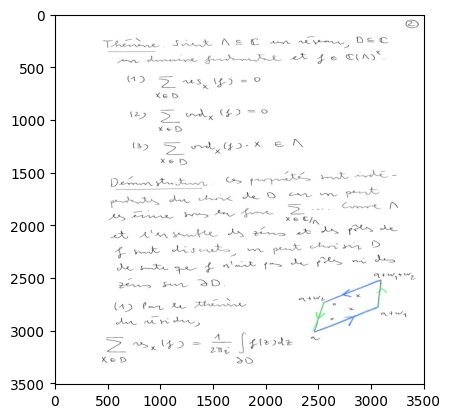

In [ ]:
(h, w) = image.shape[:2]
resize_dim = max(h, w) # ou min ?
img_resized = cv2.resize(image, (resize_dim, resize_dim), interpolation=cv2.INTER_AREA)
cv2_imshow(img_resized)

In [ ]:
img_resized.shape

(3508, 3508, 3)

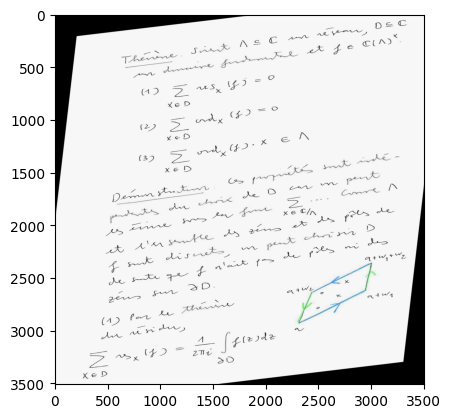

In [ ]:
#img_resized_gray = cv2.cvtColor(img_resized, cv2.COLOR_RGB2GRAY)
#F = images.Image(img_resized_gray)
F = img_resized

# FAUT DECOMMENTER le test QUELQUES CELLULES AVANT

G_data = tests[-2]
(h, w) = G_data.shape[:2]
resize_dim = max(h, w)
G_data_resized = cv2.resize(G_data, (resize_dim, resize_dim), interpolation=cv2.INTER_AREA)
#G_gray = cv2.cvtColor(G_data_resized, cv2.COLOR_RGB2GRAY)
cv2_imshow(G_data_resized)
#G = images.Image(G_gray)
G = G_data_resized

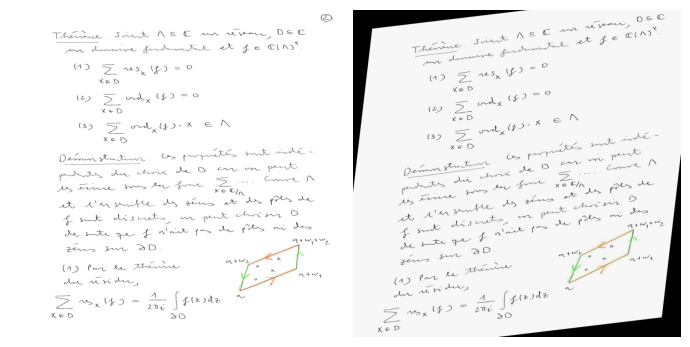

In [ ]:
plots.two_imshow(F, G)

In [ ]:
#alignment_l2 = align.align_euclidean(F, G)
import numpy as np
from fast_image_align_ot import distances

ny, nx, _ = F.shape
angles = np.linspace(0, 360, ny, endpoint=False)
dists = distances.real_space_rotational_distances(F, G, angles)

In [ ]:
!pip install POT

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.2/40.2 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 77.7 MB/s eta 0:00:00


In [ ]:
import ot
import torch
import numpy as np
import cv2

# calcul exact trop long.
def compute_gw_distance_gpu(img1, img2, size=64):
    """
    Calcule la distance de Gromov-Wasserstein sur GPU.
    """
    device = 'cuda' if torch.cuda.is_available() else 'cpu'
    print(device)
    
    # Prétraitement -> CPU
    gray1 = cv2.cvtColor(img1, cv2.COLOR_RGB2GRAY).astype(np.float32)
    gray2 = cv2.cvtColor(img2, cv2.COLOR_RGB2GRAY).astype(np.float32)
    res1 = cv2.resize(gray1, (size, size))
    res2 = cv2.resize(gray2, (size, size))

    # Inversion (encre = masse) et normalisation
    mass1 = 255.0 - res1
    mass2 = 255.0 - res2

    # Conversion en Tensors PyTorch et transfert sur GPU
    p = torch.from_numpy(mass1.ravel() / mass1.sum()).to(device)
    q = torch.from_numpy(mass2.ravel() / mass2.sum()).to(device)

    # Création des coordonnées des pixels (normalisées entre 0 et 1)
    x = torch.linspace(0, 1, size, device=device)
    y = torch.linspace(0, 1, size, device=device)
    grid_y, grid_x = torch.meshgrid(y, x, indexing='ij')
    coords = torch.stack([grid_x.reshape(-1), grid_y.reshape(-1)], dim=1)

    # Calcul de la matrice de structure (Distances intra-image) sur GPU
    # distance euclidienne au carré
    C = torch.cdist(coords, coords, p=2)**2
    C /= C.max()

    # Calcul de Gromov-Wasserstein (Backend Torch)
    # L'algorithme s'exécute sur le GPU car les entrées (C, p, q) sont sur 'cuda'
    gw_dist = ot.gromov.gromov_wasserstein2(
        C, C, p, q,
        loss_fun='square_loss',
        armijo=False, # Désactivé pour plus de vitesse sur GPU
        log=False
    )

    return gw_dist.item()

 # 'image' : référence, 'tests' : liste d'images augmentées
dist_ref_test0 = compute_gw_distance_gpu(image, tests[0], size=64)
print(f"Distance GW (GPU) : {dist_ref_test0:.8f}")

cuda


KeyboardInterrupt: 

In [ ]:
import ot
import torch
import numpy as np
import cv2

def compute_fast_gw_gpu(img1, img2, n_points=500, epsilon=0.01):
    """
    Version ultra-rapide : Entropique + Sous-échantillonnage de points
    """
    device = 'cuda' if torch.cuda.is_available() else 'cpu'

    def get_point_cloud(img, n):
        # Passage en gris et inversion (l'encre devient la masse)
        gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
        mass = 255.0 - gray

        # On récupère les coordonnées des pixels les plus sombres
        coords = np.argwhere(mass > 20) # Seuil pour ignorer le bruit de fond
        weights = mass[mass > 20]

        # Sous-échantillonnage pour garder exactement n_points
        if len(coords) > n:
            idx = np.random.choice(len(coords), n, replace=False)
            coords = coords[idx]
            weights = weights[idx]

        # Normalisation
        coords = coords / np.max(coords)
        weights = weights / weights.sum()

        return torch.from_numpy(coords).float().to(device), \
               torch.from_numpy(weights).float().to(device)

    # Extraction des nuages de points (beaucoup plus léger que des images entières)
    X1, w1 = get_point_cloud(img1, n_points)
    X2, w2 = get_point_cloud(img2, n_points)

    # Calcul des matrices de distances internes (sur GPU)
    C1 = torch.cdist(X1, X1, p=2)**2
    C2 = torch.cdist(X2, X2, p=2)**2

    # Normalisation des coûts pour la stabilité
    C1 /= C1.max()
    C2 /= C2.max()

    # Sinkhorn-Gromov-Wasserstein (Entropique)
    # epsilon est le paramètre de régularisation : plus il est grand, plus c'est rapide (mais moins précis)
    gw_dist = ot.gromov.entropic_gromov_wasserstein2(
        C1, C2, w1, w2,
        epsilon=epsilon,
        loss_fun='square_loss'
    )
    #gw_dist = ot.gromov.sliced_gromov_wasserstein2(C1, C2, w1, w2, n_projections=50)

    return gw_dist.item()

# Test
for idx, test in enumerate(tests):
  dist = compute_fast_gw_gpu(image, test, n_points=500, epsilon=0.05)
  print(f"Distance {idx} : {dist:.6f}")

/usr/local/lib/python3.12/dist-packages/ot/bregman/_sinkhorn.py:666: UserWarning: Sinkhorn did not converge. You might want to increase the number of iterations `numItermax` or the regularization parameter `reg`.
  warnings.warn(


Distance 0 : 0.033651
Distance 1 : 0.038293
Distance 2 : 0.030879
Distance 3 : 0.030566
Distance 4 : 0.030700
Distance 5 : 0.034536
Distance 6 : 0.038808
Distance 7 : 0.032469
Distance 8 : 0.035273
Distance 9 : 0.030607


In [ ]:
import ot
import torch
import numpy as np
import cv2
import matplotlib.pyplot as plt
import seaborn as sns

def get_points_from_image(img, n_points=500, device='cuda'):
    """Extrait les coordonnées des pixels d'encre (masse)"""
    if len(img.shape) == 3:
        gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    else:
        gray = img

    # Inversion : l'encre devient positive. On seuille pour ignorer le bruit.
    mass = 255.0 - gray
    mass[mass < 30] = 0

    # Récupération des coordonnées (y, x)
    coords = np.argwhere(mass > 0)
    weights = mass[mass > 0]

    if len(coords) == 0:
        return torch.zeros((n_points, 2)).to(device), torch.ones(n_points).to(device) / n_points

    # Sous-échantillonnage aléatoire pondéré pour garder n_points
    if len(coords) > n_points:
        idx = np.random.choice(len(coords), n_points, replace=False, p=weights/weights.sum())
        coords = coords[idx]
        weights = weights[idx]

    # Normalisation des coordonnées entre 0 et 1 pour l'invariance d'échelle
    coords = coords.astype(np.float32)
    coords /= np.max(coords)

    # Transfert vers GPU
    return torch.from_numpy(coords).to(device), torch.from_numpy(weights / weights.sum()).to(device)

def fast_gw_distance(img1, img2, n_points=500, epsilon=0.05):
    """Calcule la distance GW entropique sur GPU"""
    device = 'cuda' if torch.cuda.is_available() else 'cpu'

    X1, w1 = get_points_from_image(img1, n_points, device)
    X2, w2 = get_points_from_image(img2, n_points, device)

    # Matrices de coût interne (euclidienne au carré)
    C1 = torch.cdist(X1, X1, p=2)**2
    C2 = torch.cdist(X2, X2, p=2)**2

    # Normalisation pour la stabilité
    C1 = C1 / C1.max()
    C2 = C2 / C2.max()

    # Calcul de la distance de Gromov-Wasserstein Entropique
    dist = ot.gromov.entropic_gromov_wasserstein2(
        C1, C2, w1, w2, epsilon=epsilon, loss_fun='square_loss'
    )
    return dist.item()

# On compare l'image de référence avec ses versions augmentées (dans votre liste 'tests')
dists_intra = []
for aug_img in tests:
    d = compute_fast_gw_gpu(image, aug_img, n_points=500, epsilon=0.05)
    dists_intra.append(d)

# dist_inter = fast_gw_distance(image, image_ref_2)

print(f"Distance Intra-classe moyenne : {np.mean(dists_intra):.6f}")

/usr/local/lib/python3.12/dist-packages/ot/bregman/_sinkhorn.py:666: UserWarning: Sinkhorn did not converge. You might want to increase the number of iterations `numItermax` or the regularization parameter `reg`.
  warnings.warn(


KeyboardInterrupt: 

In [ ]:
import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

csv_path = os.path.join(BASE_PATH, "albu_impact.csv")
if not os.path.exists(csv_path):
    raise FileNotFoundError(f"Le fichier {csv_path} est introuvable.")

df = pd.read_csv(csv_path)

sns.set_theme(style="whitegrid", font_scale=1.1)

df['classe'] = df['filename'].apply(lambda x: x.split('_synthetic_')[0])

df['MSE'] = pd.to_numeric(df['MSE'])
df['SSIM'] = pd.to_numeric(df['SSIM'])
df['Color_Shift'] = pd.to_numeric(df['Color_Shift'])

df_class_agg_mean = df.groupby('classe')[['MSE', 'SSIM', 'Color_Shift']].mean()
df_class_agg_std = df.groupby('classe')[['MSE', 'SSIM', 'Color_Shift']].std()

annotations = df_class_agg_mean.copy()
for col in annotations.columns:
    mean_vals = df_class_agg_mean[col].tolist()
    std_vals = df_class_agg_std[col].tolist()
    annotations[col] = [f"{m:.2f}\n±{s:.2f}" for m, s in zip(mean_vals, std_vals)]

# fig, ax = plt.subplots(figsize=(10, 8))
# sns.heatmap(df_class_agg_mean, annot=annotations, fmt='', cmap="RdYlBu_r", cbar_kws={'label': 'Moyenne (Impact)'}, ax=ax)

# ax.set_title('Impact Global - Point de Vue Macro par Classe (Moyenne +/- Écart-type)', fontsize=14, fontweight='bold')
# ax.set_xlabel('Métrique Métrique', fontsize=12)
# ax.set_ylabel('Classe (Nom abrégé)', fontsize=12)
# plt.tight_layout()
# plt.savefig('heatmap_macro_agreguee.png', dpi=300)
# plt.close()


df_melted = df.melt(id_vars=['classe'],
                    value_vars=['MSE', 'SSIM', 'Color_Shift'],
                    var_name='metric', value_name='value')

g = sns.catplot(kind='box', data=df_melted, y='classe', x='value', col='metric',
                height=7, aspect=1.2, palette='viridis', sharex=False)

g.set_titles("Dispersion {col_name}", fontsize=14, fontweight='bold')
g.set_axis_labels("Valeur Métrique", "Document")

g.figure.subplots_adjust(left=0.25)

plt.savefig('dispersions_condensees_intra_classe_FIX.png', dpi=300)
plt.close()


df_for_pairplot = df[['classe', 'MSE', 'SSIM', 'Color_Shift']]

g = sns.pairplot(df_for_pairplot, hue='classe', corner=True, diag_kind='kde',
                 plot_kws={'alpha': 0.6, 's': 30, 'edgecolor': 'none'})

g._legend.remove()

#g.figure.suptitle('Point de Vue Macro - Relations Inter-Métriques', y=1.02, fontsize=14, fontweight='bold')
g.figure.subplots_adjust(right=0.8, bottom=0.1)

#sns.move_legend(g, "upper left", bbox_to_anchor=(0.82, 0.75), title='Classes')


plt.savefig('pairplot_macro_dispersion_FIX.png', dpi=300)
plt.close()

/tmp/ipykernel_3879/1635304672.py:65: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  g = sns.catplot(kind='box', data=df_melted, y='classe', x='value', col='metric',
